# Notebook 29 — Joint calibration of additive recurrence, STD, and inhibition

## Research question

Can an **additive, short-term depressing autapse** with an absolute refractory period produce **better** persistence, competitive replacement and spatial generalization than the approved **ESCM 2.0 + fading** model, **without any sensory-support state**?

The previous experiments (Notebooks 26–28) showed that our STD candidates can fade without external input but often accumulate enough excitation to resist inhibition. These mechanisms must be calibrated **together**, since spike frequency controls both depression and the inhibitory response.

We therefore separate the computation into:

1. **Isolated-neuron screen:** Find useful combinations of synaptic strength, utilization, recovery time, excitatory decay, and refractoriness. Apply a fixed inhibitory perturbation to distinguish persistence from suppression susceptibility.
2. **Spatial development:** Vary lateral inhibitory gain and decay with the surviving excitatory candidates, using **vertical and horizontal only**.
3. **Locked validation:** Compare the best candidate against ESCM 2.0 on the remaining six geometries, 16 asynchronous timing conditions and numerical timestep robustness. Never tune using held-out results.

**Benchmark is not a ceiling.** A candidate is preferred if it improves held-out replacement while preserving isolated persistence, eventual fading, low off-target firing, and numerical stability. All neurons and synapses use Brian2's conventional spike/reset, additive currents, fixed spatial inhibition, and event-driven STD. No shape labels are provided to either model.

The full historical suite's six “held-out” shapes are withheld from *this notebook's* parameter search; three were already studied in earlier notebooks and are **not historically novel**. The three new structures were also previously inspected in Notebook 28, so this is a reproducible validation split rather than a claim of an untouched external test set.


## 1. Reproduce the spatial topology and stimuli

Use the **same 9 × 9 lattice, eight geometric pairs, camera events and distance-based inhibitory graph** as Notebook 28. The two development pairs are vertical and horizontal; all other geometries are locked away from parameter selection. The camera supplies three events per pixel, at 2, 4 and 6 ms for the old pattern, and normally at 20, 22 and 24 ms for the new one.

/home/bmaacaron-iit.local/.virtualenvs/event-scm/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


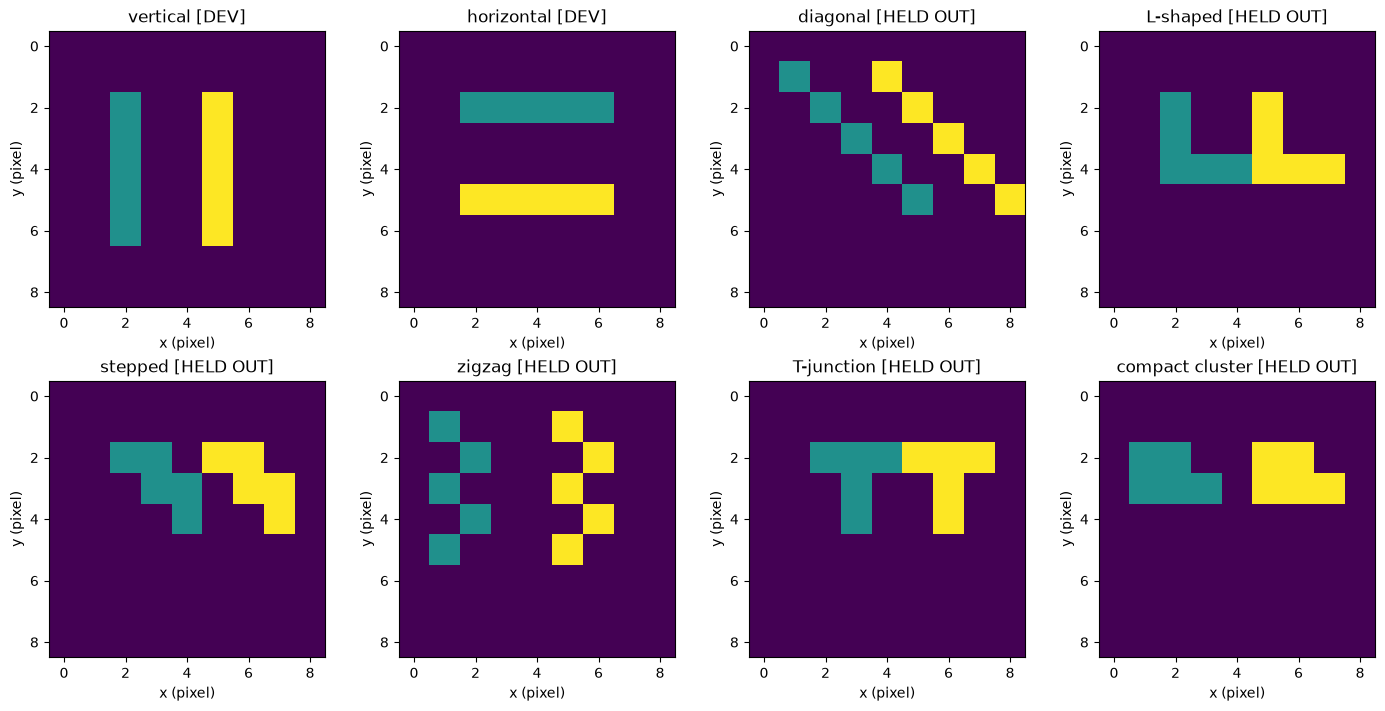

81 neurons, 3620 inhibitory synapses, 2 development and 6 held-out geometries


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import brian2 as b2

b2.prefs.codegen.target = "numpy"  # Many short experiments; no repeated C++ builds.


width = height = 9
n = width * height
xy = np.column_stack((np.arange(n) % width, np.arange(n) // width))
dt_ms = 0.05

def pixels(coords):
    return np.array([y * width + x for x, y in coords], dtype=int)

# Exact geometry definitions from Notebook 19 / 20.
shapes = {
    "vertical": (pixels([(2, y) for y in range(2, 7)]),
                 pixels([(5, y) for y in range(2, 7)])),
    "horizontal": (pixels([(x, 2) for x in range(2, 7)]),
                   pixels([(x, 5) for x in range(2, 7)])),
    "diagonal": (pixels([(x, x) for x in range(1, 6)]),
                 pixels([(x + 3, x) for x in range(1, 6)])),
    "L-shaped": (pixels([(2, 2), (2, 3), (2, 4), (3, 4), (4, 4)]),
                 pixels([(5, 2), (5, 3), (5, 4), (6, 4), (7, 4)])),
    "stepped": (pixels([(2, 2), (3, 2), (3, 3), (4, 3), (4, 4)]),
                pixels([(5, 2), (6, 2), (6, 3), (7, 3), (7, 4)])),
}

# Reused, homogeneous surround graph (same for both models and all input shapes).
distance = np.linalg.norm(xy[:, None, :] - xy[None, :, :], axis=-1)
post, pre = np.where((distance > 1.5) & (distance <= 5.5))
base_inhibition = 0.1 * np.exp(-distance[post, pre]**2 / (2 * 2.5**2))
assert all(len(a) == len(b) == 5 and len(set(a) | set(b)) == 10
           for a, b in shapes.values())


# Three fixed, previously untested structures; excluded from parameter selection.
heldout_shapes = {
    "zigzag": (pixels([(1, 1), (2, 2), (1, 3), (2, 4), (1, 5)]),
               pixels([(5, 1), (6, 2), (5, 3), (6, 4), (5, 5)])),
    "T-junction": (pixels([(2, 2), (3, 2), (4, 2), (3, 3), (3, 4)]),
                   pixels([(5, 2), (6, 2), (7, 2), (6, 3), (6, 4)])),
    "compact cluster": (pixels([(1, 2), (2, 2), (1, 3), (2, 3), (3, 3)]),
                        pixels([(5, 2), (6, 2), (5, 3), (6, 3), (7, 3)])),
}
shapes.update(heldout_shapes)
development = ("vertical", "horizontal")
validation = ("diagonal", "L-shaped", "stepped", *heldout_shapes)
assert set(development).isdisjoint(validation)
assert all(len(a) == len(b) == 5 and len(set(a) | set(b)) == 10
           for a, b in shapes.values())
fig, axes = plt.subplots(2, 4, figsize=(14, 7), constrained_layout=True)
for ax, (name, (old, new)) in zip(axes.flat, shapes.items()):
    grid = np.zeros(n, dtype=int)
    grid[old], grid[new] = 1, 2
    ax.imshow(grid.reshape(height, width), vmin=0, vmax=2,
              cmap="viridis", interpolation="nearest")
    ax.set(title=name + (" [DEV]" if name in development else " [HELD OUT]"),
           xlabel="x (pixel)", ylabel="y (pixel)",
           xticks=range(0, 9, 2), yticks=range(0, 9, 2))
for ax in list(axes.flat)[len(shapes):]:
    ax.axis("off")
plt.show()
print(f"{n} neurons, {len(pre)} inhibitory synapses, "
      f"{len(development)} development and {len(validation)} held-out geometries")

## 2. Models and parameters

Every neuron obeys

\[
\tau_m\dot v=-v+I_{\rm ext}+I_{\rm exc}-I_{\rm inh},\qquad
\tau_a\dot I_a=-I_a\quad(a\in\{\rm ext,exc,inh\}).
\]

The approved ESCM 2.0 baseline uses its **unchanged** settings: \(\tau_m=10\) ms, \(\tau_{\rm exc}=5\) ms, \(\tau_{\rm inh}=12\) ms, sensory support decay 120 ms, refreshed recurrence \(I_{\rm exc}\leftarrow 8\,support\), no refractory period, and spatial inhibition multiplier 1.

The new candidate **has no `support` variable**. Its autapse uses a synaptic resource \(x\in[0,1]\), initially 1, with

\[
\tau_{\rm rec}\dot x=1-x,\qquad
I_{\rm exc}\leftarrow I_{\rm exc}+J_0x,\qquad
x\leftarrow (1-U)x.
\]

`J0`, `U`, recovery, excitatory and inhibitory current time constants, refractory period and inhibition gain are experimentally varied. Membrane time constant stays at 10 ms in the initial search to constrain computation; varying \(\tau_m\) would be a separate extension if these operating regimes fail. Camera excitation, threshold, and the *shape of the spatial inhibitory kernel* stay unchanged. The absolute refractory period prevents further spikes but does **not** freeze membrane or synaptic currents.


In [2]:
def simulate(schedule, *, mode, weight, refractory_ms, U=0.05, tau_rec_ms=80.,
             tau_exc_ms=5., tau_inh_ms=12., tau_m_ms=10., inhibition_gain=1.,
             duration_ms=260., n_neurons=n, trace_ids=None, dt=dt_ms,
             probe_times=(), probe_strength=0.):
    b2.start_scope()
    b2.defaultclock.dt = dt * b2.ms

    event_ids, event_times = [], []
    for ids, pulses, stagger_ms in schedule:
        for pulse in pulses:
            for j, pixel in enumerate(ids):
                event_ids.append(int(pixel))
                event_times.append(float(pulse) + j*stagger_ms)
    order = np.argsort(event_times, kind="stable")
    camera = b2.SpikeGeneratorGroup(
        n_neurons, np.asarray(event_ids, dtype=int)[order],
        np.asarray(event_times, dtype=float)[order]*b2.ms)

    parameters = dict(tau_m=tau_m_ms*b2.ms, tau_ext=3*b2.ms,
                      tau_exc=tau_exc_ms*b2.ms, tau_inh=tau_inh_ms*b2.ms,
                      tau_support=120*b2.ms, v_threshold=1., camera_gain=22.)
    equations = """
        dv/dt = (-v + Iext + Iexc - Iinh)/tau_m : 1
        dIext/dt = -Iext/tau_ext : 1
        dIexc/dt = -Iexc/tau_exc : 1
        dIinh/dt = -Iinh/tau_inh : 1
    """
    if mode == "refresh":
        equations += "dsupport/dt = -support/tau_support : 1\n"
    neurons = b2.NeuronGroup(
        n_neurons, equations, threshold="v > v_threshold", reset="v = 0",
        refractory=refractory_ms*b2.ms if refractory_ms else False,
        method="exact", namespace=parameters)

    camera_update = "Iext_post += camera_gain"
    if mode == "refresh":
        camera_update += "; support_post = 1"
    feed = b2.Synapses(camera, neurons, on_pre=camera_update, namespace=parameters)
    feed.connect(j="i")

    if mode == "std":
        recurrence = b2.Synapses(
            neurons, neurons, "dx/dt = (1-x)/tau_recovery : 1 (event-driven)",
            on_pre="Iexc_post += std_increment*x; x = x*(1-std_utilization)",
            namespace={"std_increment": float(weight), "std_utilization": float(U),
                       "tau_recovery": float(tau_rec_ms)*b2.ms})
    elif mode == "refresh":
        recurrence = b2.Synapses(
            neurons, neurons, on_pre="Iexc_post = recurrence_gain*support_post",
            namespace={"recurrence_gain": float(weight)})
    else:
        raise ValueError(mode)
    recurrence.connect(i=np.arange(n_neurons), j=np.arange(n_neurons))
    if mode == "std":
        recurrence.x = 1.

    spikes = b2.SpikeMonitor(neurons)
    objects = [camera, neurons, feed, recurrence, spikes]
    if n_neurons == n:
        inhibition = b2.Synapses(neurons, neurons, "w : 1", on_pre="Iinh_post += w")
        inhibition.connect(i=pre, j=post)
        inhibition.w = base_inhibition*inhibition_gain
        objects.append(inhibition)

    # Controlled perturbation is only used in the isolated-neuron screen;
    # spatial validation receives its inhibition exclusively from other neurons.
    if probe_times:
        perturb = b2.SpikeGeneratorGroup(1, np.zeros(len(probe_times), dtype=int),
                                        np.asarray(probe_times)*b2.ms)
        probe = b2.Synapses(perturb, neurons,
                           on_pre="Iinh_post += probe_strength",
                           namespace={"probe_strength": float(probe_strength)})
        probe.connect(i=0, j=0)
        objects.extend([perturb, probe])

    if trace_ids is not None:
        variables = ["v", "Iext", "Iexc", "Iinh"]
        if mode == "refresh":
            variables.append("support")
        state = b2.StateMonitor(neurons, variables, record=trace_ids)
        objects.append(state)
        if mode == "std":
            resource = b2.StateMonitor(recurrence, "x", record=trace_ids)
            objects.append(resource)

    b2.Network(*objects).run(duration_ms*b2.ms)
    result = {"t": np.asarray(spikes.t/b2.ms), "i": np.asarray(spikes.i, dtype=int)}
    if trace_ids is not None:
        result["time"] = np.asarray(state.t/b2.ms)
        for var in variables:
            result[var] = np.asarray(getattr(state, var))
        if mode == "std":
            result["x"] = np.asarray(resource.x)
    return result

reference = dict(mode="refresh", weight=8., refractory_ms=0.)
old_pulses = (2., 4., 6.)

def pulse_schedule(old, new, second_start=20., row_delay=0.):
    return ((old, old_pulses, row_delay),
            (new, (second_start, second_start+2., second_start+4.), row_delay))

solo_schedule = [(np.array([0], dtype=int), old_pulses, 0.)]
reference_solo = simulate(solo_schedule, **reference, n_neurons=1, trace_ids=[0])
print("ESCM 2.0 reference isolated last spike (ms):", float(reference_solo["t"][-1]))

ESCM 2.0 reference isolated last spike (ms): 89.2


## 3. Screen isolated-neuron operating regimes, including inhibitory susceptibility

A candidate must remain active after the camera stops, but not indefinitely. An isolated neuron is stimulated at 2, 4 and 6 ms; we measure spikes in **[20,32) ms**, **[32,52) ms**, and the camera-silent tail **[200,260) ms**. We also measure firing intervals.

To assess suppressibility separately from geometry, present **three identical inhibitory events** at 20, 22 and 24 ms, each adding 3 current units. This perturbation is a *diagnostic*, **not a model parameter**. Compare the perturbed and unperturbed output during [32,52) ms. A larger reduction indicates greater inhibitory susceptibility, but the eventual spatial network must generate inhibition on its own.

Rather than optimizing only persistence time, screen a bounded grid of \(J_0\), \(U\), \(\tau_{\rm rec}\), \(\tau_{\rm exc}\), and \(t_{\rm ref}\). The joint influence of inhibition strength and decay is tested in the spatial stage. The search is finite, heuristic, and **does not establish a globally optimal solution**.


Isolated STD operating regimes:   1%|▏         | 1/72 [00:00<01:06,  1.07it/s]WARNING    The name "tau_exc" refers to different objects in different namespaces used for resolving names in the context of group "neurongroup". Will use the object from the group-specific namespace with the value 3. * msecond, but the name also refers to a variable in the run namespace with value '3.0'. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    't' is an internal variable of group 'synapses_1', but also exists in the run namespace with the value array([ 2.55,  3.55,  4.55, ..., 17.4 , 19.35, 22.3 ], shape=(17,)). The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
Isolated STD operating regimes:   3%|▎         | 2/72 [00:01<00:38,  1.84it/s]WARNING    The name "tau_exc" refers to different objects in different namespaces used for resolving names in the context of group "neurongroup_1". Will use the object from the group-specific namespace with

Viable isolated candidates: 14/72


,J0,U,tau_rec_ms,tau_exc_ms,refractory_ms,early_spikes,late_spikes,late_inhibited_spikes,susceptibility,tail_spikes,last_spike_ms,min_isi_ms
52,8.0,0.025,100.0,3.0,1.0,12,20,0.0,1.0,0,73.80,1.0
6,3.0,0.025,100.0,6.0,1.0,12,15,0.0,1.0,0,69.55,1.0
7,3.0,0.025,100.0,6.0,2.0,6,10,0.0,1.0,0,98.60,2.0
39,5.0,0.060,100.0,6.0,2.0,6,10,0.0,1.0,0,87.15,2.0
25,5.0,0.025,40.0,3.0,2.0,6,10,0.0,1.0,0,69.15,2.0
71,8.0,0.120,100.0,6.0,2.0,6,9,0.0,1.0,0,62.65,2.0
38,5.0,0.060,100.0,6.0,1.0,12,9,0.0,1.0,0,54.20,1.0
11,3.0,0.060,40.0,6.0,2.0,6,8,0.0,1.0,0,60.15,2.0
24,5.0,0.025,40.0,3.0,1.0,11,8,0.0,1.0,0,47.25,1.0
29,5.0,0.025,100.0,3.0,2.0,6,7,0.0,1.0,0,48.30,2.0


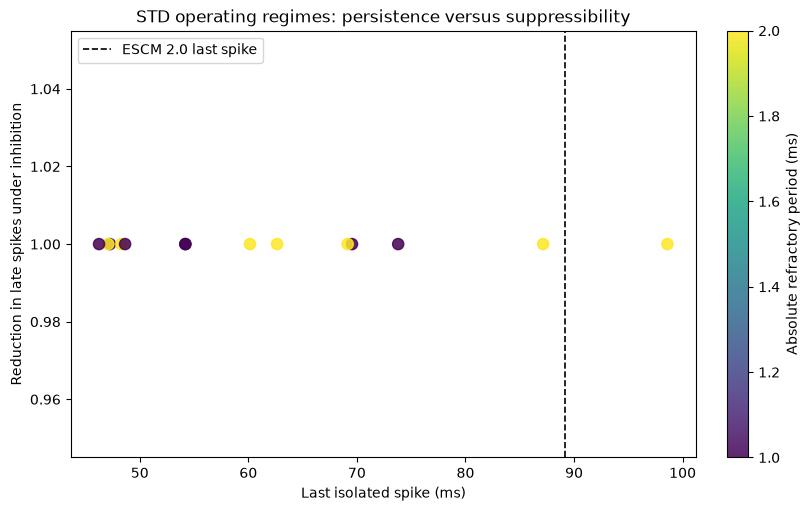

In [3]:
from itertools import product

# Change these lists to broaden the screen, not the evaluation protocol.
excitation_grid = [3., 5., 8.]
utilization_grid = [0.025, 0.06, 0.12]
recovery_grid_ms = [40., 100.]
exc_decay_grid_ms = [3., 6.]
refractory_grid_ms = [1., 2.]

solo_rows = []
settings_grid = list(product(excitation_grid, utilization_grid,
                             recovery_grid_ms, exc_decay_grid_ms,
                             refractory_grid_ms))
for J0, U, tau_rec, tau_exc, refractory in tqdm(settings_grid, desc="Isolated STD operating regimes"):
    cfg = dict(mode="std", weight=J0, U=U, tau_rec_ms=tau_rec,
               tau_exc_ms=tau_exc, refractory_ms=refractory)
    unperturbed = simulate(solo_schedule, **cfg, n_neurons=1)
    t = unperturbed["t"]
    early = np.sum((t >= 20.) & (t < 32.))
    late = np.sum((t >= 32.) & (t < 52.))
    tail = np.sum(t >= 200.)
    # Measure inhibition response only when the candidate persists through the challenge.
    if early >= 3 and late >= 5 and tail == 0:
        inhibited = simulate(solo_schedule, **cfg, n_neurons=1, duration_ms=65.,
                             probe_times=(20., 22., 24.), probe_strength=3.)
        perturbed_late = np.sum((inhibited["t"] >= 32.) & (inhibited["t"] < 52.))
        susceptibility = 1 - perturbed_late/late
    else:
        perturbed_late = np.nan
        susceptibility = np.nan
    solo_rows.append(dict(J0=J0, U=U, tau_rec_ms=tau_rec, tau_exc_ms=tau_exc,
                          refractory_ms=refractory, early_spikes=int(early),
                          late_spikes=int(late), late_inhibited_spikes=perturbed_late,
                          susceptibility=susceptibility, tail_spikes=int(tail),
                          last_spike_ms=float(t[-1]) if len(t) else np.nan,
                          min_isi_ms=float(np.diff(t).min()) if len(t)>1 else np.nan))

single = pd.DataFrame(solo_rows)
viable = single[(single.early_spikes >= 3) & (single.late_spikes >= 5) &
                (single.tail_spikes == 0)].copy()
# Favor responses to inhibition, followed by persistence margin; retain parameter diversity.
viable = viable.sort_values(["susceptibility", "late_spikes", "last_spike_ms"],
                            ascending=[False, False, False])
print(f"Viable isolated candidates: {len(viable)}/{len(single)}")
display(viable.head(15).round(3))
assert len(viable), "No candidate satisfies the operating criteria; expand the isolated grid before spatial calibration."

fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
sc = ax.scatter(viable.last_spike_ms, viable.susceptibility,
                c=viable.refractory_ms, cmap="viridis", s=65, alpha=.85)
ax.axvline(reference_solo["t"][-1], ls="--", color="black", lw=1.2,
           label="ESCM 2.0 last spike")
ax.set(xlabel="Last isolated spike (ms)", ylabel="Reduction in late spikes under inhibition",
       title="STD operating regimes: persistence versus suppressibility")
ax.legend(loc="best")
fig.colorbar(sc, ax=ax, label="Absolute refractory period (ms)")
plt.show()

## 4. Spatial competition: jointly tune inhibition and excitatory candidates

Isolated-neuron susceptibility is only a filter. In the spatial network, inhibition arises **exclusively** from spikes of other neurons and must compete with the selected excitatory regime. For each of the most promising isolated configurations, vary the inhibitory gain and decay time constant, measuring vertical and horizontal replacement. A configuration is **eligible** only when *both patterns persist alone* throughout the two evaluation windows. Successful replacement requires all five new pixels active, all five obsolete pixels silent, and no spurious pixels.

The ranking prioritizes strict replacement and eligible controls, then per-pixel suppression and retained new activity. Only the two development geometries influence model selection. If no setting succeeds, the notebook reports that rather than claiming a match to ESCM 2.0.

In [4]:
def pixel_counts(run, ids, start, stop):
    mask = (run["t"] >= start) & (run["t"] < stop)
    return np.bincount(run["i"][mask], minlength=n)[ids]

def evaluate_one(geometry, setting, *, second_start=20., row_delay=0., dt=dt_ms):
    old, new = shapes[geometry]
    old_input, new_input = pulse_schedule(old, new, second_start, row_delay)
    # Evaluate at a fixed delay from the most recent new-camera event.
    evaluation_windows = ((second_start + 12., second_start + 22.),
                          (second_start + 22., second_start + 32.))
    end_ms = max(80., second_start+44.)
    old_only = simulate([old_input], **setting, duration_ms=end_ms, dt=dt)
    new_only = simulate([new_input], **setting, duration_ms=end_ms, dt=dt)
    both = simulate([old_input, new_input], **setting, duration_ms=end_ms, dt=dt)
    outside = np.setdiff1d(np.arange(n), np.r_[old, new])

    def per_window(run, ids):
        return np.array([pixel_counts(run, ids, a, b) for a, b in evaluation_windows])

    old_ctrl = (per_window(old_only, old) >= 2).all(axis=0)
    new_ctrl = (per_window(new_only, new) >= 2).all(axis=0)
    old_quiet = (per_window(both, old) == 0).all(axis=0)
    new_active = (per_window(both, new) >= 2).all(axis=0)
    off_target = (per_window(both, outside) > 0).any(axis=0)
    eligible = bool(old_ctrl.all() and new_ctrl.all())
    success = bool(eligible and old_quiet.all() and new_active.all() and not off_target.any())
    last_old = both["t"][np.isin(both["i"], old)]
    last_old_after_new = last_old[last_old >= second_start]
    # A useful latency must correspond to actual suppression, not later fading.
    latency = (float(last_old_after_new[-1] - (second_start+4.+4*row_delay))
               if eligible and old_quiet.all() and len(last_old_after_new) else np.nan)
    return dict(geometry=geometry, eligible=eligible, success=success,
                old_control=int(old_ctrl.sum()), new_control=int(new_ctrl.sum()),
                old_silent=int(old_quiet.sum()), new_persistent=int(new_active.sum()),
                off_target=int(off_target.sum()), suppression_latency_ms=latency)

def geometry_table(setting, names):
    return pd.DataFrame([evaluate_one(name, setting) for name in names])

# Reproduce the development benchmark before the search.
benchmark_dev = geometry_table(reference, development)
display(benchmark_dev)
assert benchmark_dev.success.all(), "ESCM 2.0 benchmark mismatch: inspect equations/stimuli before calibration."

# Keep multiple families of excitation parameters, rather than a single best scalar score.
exc_shortlist = viable.head(10)
inhibition_gains = [0.5, 1., 2., 4.]
inhibition_decays_ms = [8., 12., 18.]

search_rows = []
for row in tqdm(list(exc_shortlist.itertuples(index=False)), desc="Joint spatial calibration"):
    for gI, tau_inh in product(inhibition_gains, inhibition_decays_ms):
        cfg = dict(mode="std", weight=float(row.J0), U=float(row.U),
                   tau_rec_ms=float(row.tau_rec_ms),
                   tau_exc_ms=float(row.tau_exc_ms),
                   refractory_ms=float(row.refractory_ms),
                   inhibition_gain=gI, tau_inh_ms=tau_inh)
        results = geometry_table(cfg, development)
        search_rows.append(dict(**{k: cfg[k] for k in ("weight", "U", "tau_rec_ms",
                         "tau_exc_ms", "refractory_ms", "inhibition_gain", "tau_inh_ms")},
                         successes=int(results.success.sum()),
                         eligible=int(results.eligible.sum()),
                         old_silent=int(results.old_silent.sum()),
                         new_persistent=int(results.new_persistent.sum()),
                         off_target=int(results.off_target.sum()),
                         solo_susceptibility=float(row.susceptibility)))

search = pd.DataFrame(search_rows).sort_values(
    ["successes", "eligible", "old_silent", "new_persistent", "off_target", "solo_susceptibility"],
    ascending=[False, False, False, False, True, False]).reset_index(drop=True)
display(search.head(20).round(3))
winner = search.iloc[0]
selected_std = dict(mode="std", weight=float(winner.weight), U=float(winner.U),
                    tau_rec_ms=float(winner.tau_rec_ms), tau_exc_ms=float(winner.tau_exc_ms),
                    refractory_ms=float(winner.refractory_ms),
                    inhibition_gain=float(winner.inhibition_gain),
                    tau_inh_ms=float(winner.tau_inh_ms))
print("LOCKED model:", selected_std)
print("Development successes: ESCM 2.0", int(benchmark_dev.success.sum()),
      "/2; selected STD", int(winner.successes), "/2")

WARNING    The name "tau_exc" refers to different objects in different namespaces used for resolving names in the context of group "neurongroup_1". Will use the object from the group-specific namespace with the value 5. * msecond, but the name also refers to a variable in the run namespace with value '6.0'. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    The name "tau_exc" refers to different objects in different namespaces used for resolving names in the context of group "neurongroup". Will use the object from the group-specific namespace with the value 5. * msecond, but the name also refers to a variable in the run namespace with value '6.0'. [brian2.groups.group.Group.resolve.resolution_conflict]


,geometry,eligible,success,old_control,new_control,old_silent,new_persistent,off_target,suppression_latency_ms
0,vertical,True,True,5,5,5,5,0,-1.2
1,horizontal,True,True,5,5,5,5,0,-1.2


Joint spatial calibration:   0%|          | 0/10 [00:00<?, ?it/s]WARNING    The name "tau_exc" refers to different objects in different namespaces used for resolving names in the context of group "neurongroup_1". Will use the object from the group-specific namespace with the value 3. * msecond, but the name also refers to a variable in the run namespace with value '6.0'. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    The name "tau_inh" refers to different objects in different namespaces used for resolving names in the context of group "neurongroup_1". Will use the object from the group-specific namespace with the value 8. * msecond, but the name also refers to a variable in the run namespace with value '8.0'. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    The name "tau_exc" refers to different objects in different namespaces used for resolving names in the context of group "neurongroup". Will use the object from the group-specific namespace with 

,weight,U,tau_rec_ms,tau_exc_ms,refractory_ms,inhibition_gain,tau_inh_ms,successes,eligible,old_silent,new_persistent,off_target,solo_susceptibility
0,8.0,0.025,100.0,3.0,1.0,0.5,8.0,0,2,0,10,0,1.0
1,8.0,0.025,100.0,3.0,1.0,0.5,12.0,0,2,0,10,0,1.0
2,8.0,0.025,100.0,3.0,1.0,0.5,18.0,0,2,0,10,0,1.0
3,8.0,0.025,100.0,3.0,1.0,1.0,8.0,0,2,0,10,0,1.0
4,8.0,0.025,100.0,3.0,1.0,1.0,12.0,0,2,0,10,0,1.0
5,8.0,0.025,100.0,3.0,1.0,1.0,18.0,0,2,0,10,0,1.0
6,8.0,0.025,100.0,3.0,1.0,2.0,8.0,0,2,0,10,0,1.0
7,3.0,0.025,100.0,6.0,1.0,0.5,8.0,0,2,0,10,0,1.0
8,3.0,0.025,100.0,6.0,1.0,0.5,12.0,0,2,0,10,0,1.0
9,3.0,0.025,100.0,6.0,1.0,0.5,18.0,0,2,0,10,0,1.0


LOCKED model: {'mode': 'std', 'weight': 8.0, 'U': 0.025, 'tau_rec_ms': 100.0, 'tau_exc_ms': 3.0, 'refractory_ms': 1.0, 'inhibition_gain': 0.5, 'tau_inh_ms': 8.0}
Development successes: ESCM 2.0 2 /2; selected STD 0 /2


## 5. Locked spatial generalization

Now **freeze all parameters**. Evaluate the original five geometries plus zigzag, T-junction and compact cluster. Only vertical and horizontal were used in calibration. Report isolated eligibility separately from old suppression, new retention, spurious activity and strict success. The model is allowed to outperform ESCM 2.0: no score is capped at the baseline.

Locked spatial validation:   0%|          | 0/2 [00:00<?, ?it/s]WARNING    The name "tau_inh" refers to different objects in different namespaces used for resolving names in the context of group "neurongroup_1". Will use the object from the group-specific namespace with the value 12. * msecond, but the name also refers to a variable in the run namespace with value '18.0'. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    The name "tau_inh" refers to different objects in different namespaces used for resolving names in the context of group "neurongroup". Will use the object from the group-specific namespace with the value 12. * msecond, but the name also refers to a variable in the run namespace with value '18.0'. [brian2.groups.group.Group.resolve.resolution_conflict]
Locked spatial validation:  50%|█████     | 1/2 [00:07<00:07,  7.36s/it]WARNING    The name "tau_inh" refers to different objects in different namespaces used for resolving names in the context of group "

,model,geometry,split,eligible,success,old_control,new_control,old_silent,new_persistent,off_target,suppression_latency_ms
0,ESCM 2.0 + fading,vertical,development,True,True,5,5,5,5,0,-1.20
1,ESCM 2.0 + fading,horizontal,development,True,True,5,5,5,5,0,-1.20
2,ESCM 2.0 + fading,diagonal,held out,True,False,5,5,4,5,0,NaN
3,ESCM 2.0 + fading,L-shaped,held out,True,False,5,5,5,4,0,0.55
4,ESCM 2.0 + fading,stepped,held out,True,True,5,5,5,5,0,1.40
5,ESCM 2.0 + fading,zigzag,held out,True,True,5,5,5,5,0,0.65
6,ESCM 2.0 + fading,T-junction,held out,False,False,4,4,5,4,0,NaN
7,ESCM 2.0 + fading,compact cluster,held out,True,False,5,5,3,5,0,NaN
8,STD (locked),vertical,development,True,False,5,5,0,5,0,NaN
9,STD (locked),horizontal,development,True,False,5,5,0,5,0,NaN


,model,split,geometries,eligible,strict_success,old_silent_mean,new_persistent_mean,off_target_total
0,ESCM 2.0 + fading,development,2,2,2,5.0,5.00,0
1,ESCM 2.0 + fading,held out,6,5,2,4.5,4.67,0
2,STD (locked),development,2,2,0,0.0,5.00,0
3,STD (locked),held out,6,6,0,0.0,5.00,0


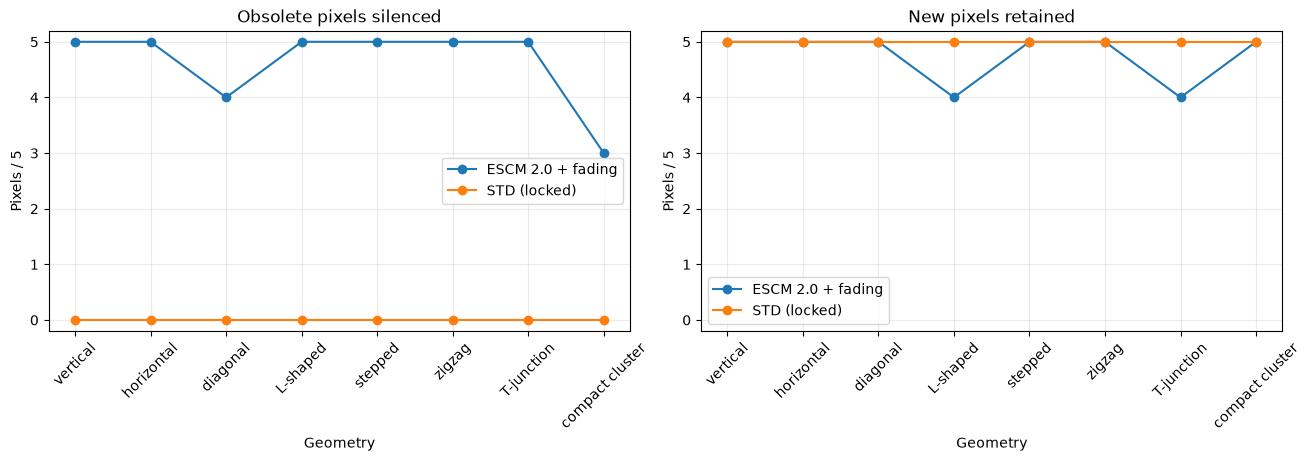

In [5]:
models = {"ESCM 2.0 + fading": reference, "STD (locked)": selected_std}
spatial_rows = []
for name, cfg in tqdm(models.items(), desc="Locked spatial validation"):
    table = geometry_table(cfg, (*development, *validation))
    table.insert(0, "model", name)
    table.insert(2, "split", np.where(table.geometry.isin(development), "development", "held out"))
    spatial_rows.append(table)
spatial = pd.concat(spatial_rows, ignore_index=True)
display(spatial)
display(spatial.groupby(["model", "split"], sort=False).agg(
    geometries=("geometry", "size"), eligible=("eligible", "sum"),
    strict_success=("success", "sum"), old_silent_mean=("old_silent", "mean"),
    new_persistent_mean=("new_persistent", "mean"), off_target_total=("off_target", "sum")
).reset_index().round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)
for ax, (metric, title) in zip(axes, [("old_silent", "Obsolete pixels silenced"),
                                       ("new_persistent", "New pixels retained")]):
    for model, rows in spatial.groupby("model", sort=False):
        ax.plot(rows.geometry, rows[metric], marker="o", ms=6, label=model)
    ax.set(title=title, xlabel="Geometry", ylabel="Pixels / 5", ylim=(-0.2, 5.2))
    ax.tick_params(axis="x", labelrotation=45)
    ax.grid(alpha=.25)
    ax.legend()
plt.show()

## 6. Held-out timing and numerical robustness

Run 16 asynchronous timing conditions on the vertical pair: four onsets × four pixel staggers, with the evaluation windows moving relative to onset. Separately, repeat **all six spatial validation pairs** at 0.1, 0.05 and 0.025 ms. This measures stability over the tested integration steps; it is not a proof of convergence. No retuning is allowed.

Temporal generalization: 100%|██████████| 2/2 [00:31<00:00, 15.50s/it]


,eligible,strict_success,old_silent_mean,new_persistent_mean
model,,,,
ESCM 2.0 + fading,15,15,5.0,5.0
STD (locked),15,0,0.0,5.0


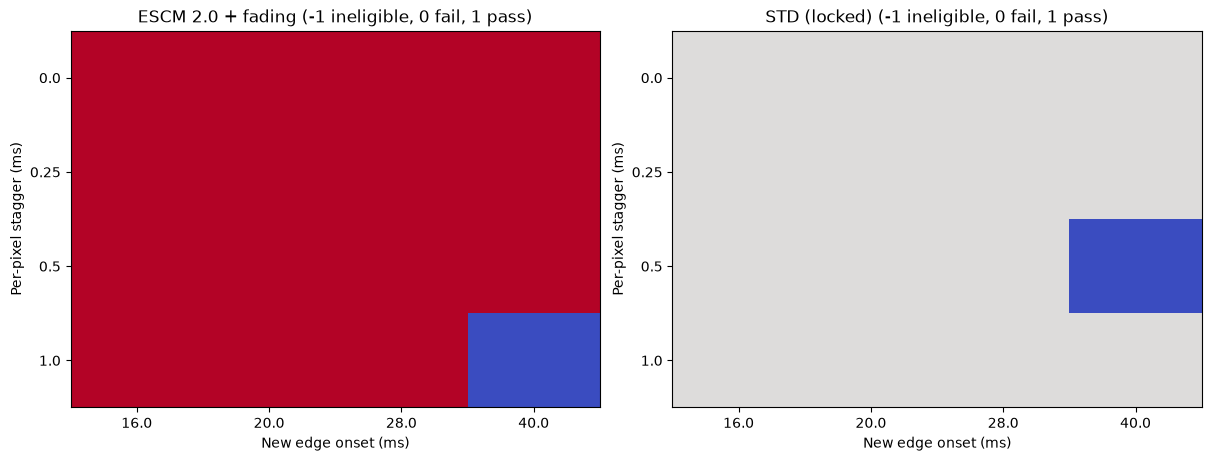

Numerical resolution: 100%|██████████| 3/3 [00:37<00:00, 12.57s/it]


,model,dt_ms,eligible,strict_success
0,ESCM 2.0 + fading,0.025,5,2
1,ESCM 2.0 + fading,0.050,5,2
2,ESCM 2.0 + fading,0.100,5,2
3,STD (locked),0.025,6,0
4,STD (locked),0.050,6,0
5,STD (locked),0.100,6,0


In [6]:
timing_rows = []
for name, cfg in tqdm(models.items(), desc="Temporal generalization"):
    for onset, stagger in product((16., 20., 28., 40.), (0., 0.25, 0.5, 1.)):
        result = evaluate_one("vertical", cfg, second_start=onset, row_delay=stagger)
        timing_rows.append(dict(model=name, onset_ms=onset, stagger_ms=stagger, **result))
timing = pd.DataFrame(timing_rows)
display(timing.groupby("model", sort=False).agg(
    eligible=("eligible", "sum"), strict_success=("success", "sum"),
    old_silent_mean=("old_silent", "mean"), new_persistent_mean=("new_persistent", "mean")))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
for ax, name in zip(axes, models):
    frame = timing[timing.model == name]
    count = frame.pivot(index="stagger_ms", columns="onset_ms", values="success")
    elig = frame.pivot(index="stagger_ms", columns="onset_ms", values="eligible")
    outcome = np.where(~elig.to_numpy(dtype=bool), -1, count.to_numpy(dtype=int))
    ax.imshow(outcome, vmin=-1, vmax=1, cmap="coolwarm", interpolation="nearest", aspect="auto")
    ax.set(title=name + " (-1 ineligible, 0 fail, 1 pass)",
           xlabel="New edge onset (ms)", ylabel="Per-pixel stagger (ms)",
           xticks=range(4), xticklabels=count.columns,
           yticks=range(4), yticklabels=count.index)
plt.show()

resolution = []
for step in tqdm((0.1, 0.05, 0.025), desc="Numerical resolution"):
    for name, cfg in models.items():
        for geometry in validation:
            result = evaluate_one(geometry, cfg, dt=step)
            resolution.append(dict(dt_ms=step, model=name, **result))
resolution = pd.DataFrame(resolution)
display(resolution.groupby(["model", "dt_ms"]).agg(
    eligible=("eligible", "sum"), strict_success=("success", "sum")
).reset_index())

## 7. Inspect the selected circuit and interpret its limits

Finally, plot the old and new edge currents and STD synaptic resource traces through recruitment and competition. In the spatial network inhibition is generated by neighboring spikes—no artificial inhibitory probes are present. If old activity survives, inspect **net current** \(I_{
m ext}+I_{
m exc}-I_{
m inh}\), not just the excitatory current. A good isolated operating point does not guarantee a good recurrent spatial network.

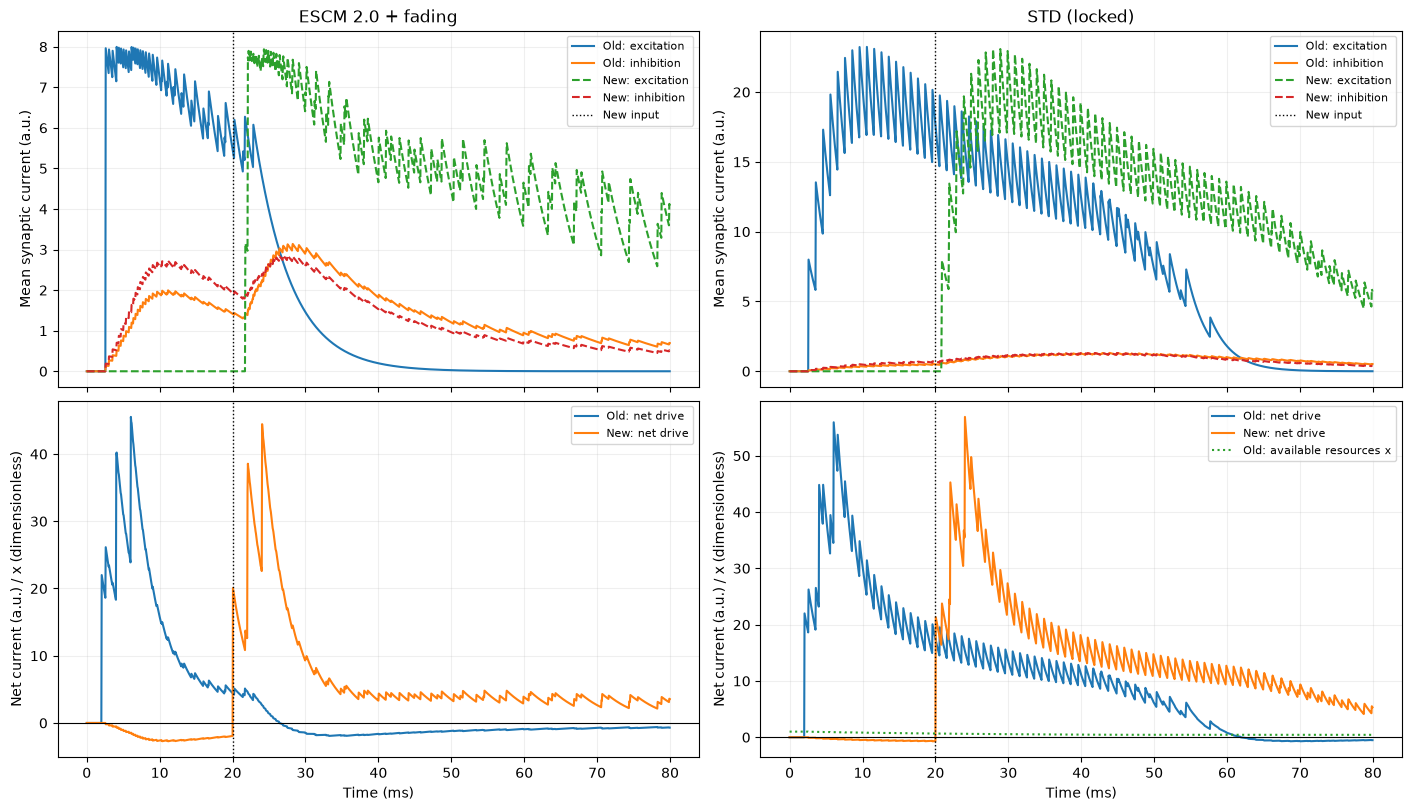

Selected STD parameters: {'mode': 'std', 'weight': 8.0, 'U': 0.025, 'tau_rec_ms': 100.0, 'tau_exc_ms': 3.0, 'refractory_ms': 1.0, 'inhibition_gain': 0.5, 'tau_inh_ms': 8.0}
Development: 0 /2
Held-out: 0 /6
Temporal: 0 /16


In [7]:
old, new = shapes["vertical"]
side_by_side = {}
for name, cfg in models.items():
    side_by_side[name] = simulate(pulse_schedule(old, new), **cfg,
                                  duration_ms=80., trace_ids=np.r_[old, new])

fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True, constrained_layout=True)
for col, (name, run) in enumerate(side_by_side.items()):
    t = run["time"]
    old_exc, new_exc = run["Iexc"][:5].mean(0), run["Iexc"][5:].mean(0)
    old_inh, new_inh = run["Iinh"][:5].mean(0), run["Iinh"][5:].mean(0)
    ax = axes[0, col]
    ax.plot(t, old_exc, label="Old: excitation")
    ax.plot(t, old_inh, label="Old: inhibition")
    ax.plot(t, new_exc, ls="--", label="New: excitation")
    ax.plot(t, new_inh, ls="--", label="New: inhibition")
    ax.axvline(20, color="black", ls=":", lw=1, label="New input")
    ax.set(title=name, ylabel="Mean synaptic current (a.u.)")
    ax.legend(fontsize=8)
    ax.grid(alpha=.2)

    ax = axes[1, col]
    net = run["Iext"] + run["Iexc"] - run["Iinh"]
    ax.plot(t, net[:5].mean(0), label="Old: net drive")
    ax.plot(t, net[5:].mean(0), label="New: net drive")
    if "x" in run:
        ax.plot(t, run["x"][:5].mean(0), ls=":", label="Old: available resources x")
    ax.axhline(0, color="black", lw=.8)
    ax.axvline(20, color="black", ls=":", lw=1)
    ax.set(xlabel="Time (ms)", ylabel="Net current (a.u.) / x (dimensionless)")
    ax.legend(fontsize=8)
    ax.grid(alpha=.2)
plt.show()

print("Selected STD parameters:", selected_std)
print("Development:", int(spatial[(spatial.model == "STD (locked)") &
                                 (spatial.split == "development")].success.sum()), "/2")
print("Held-out:", int(spatial[(spatial.model == "STD (locked)") &
                                (spatial.split == "held out")].success.sum()), "/6")
print("Temporal:", int(timing[timing.model == "STD (locked)"].success.sum()), "/16")

## 8. Conclusions to draw after running

A successful STD-based replacement requires (i) reliable isolated persistence and finite fading, (ii) early termination of obsolete activity **caused by competing inhibition**, (iii) retention of newly stimulated pixels, and (iv) generalization beyond the two development geometries. Success is **not** defined by matching the reference's precise spike rate or last-spike timestamp.

The controlled inhibitory pulse only screens individual neurons; **spatial performance must be demonstrated in the recurrent network**. The search grid is intentionally bounded, so zero successes indicates only that this tested parameter region failed. Furthermore, varying the membrane time constant or changing topology may be valuable future experiments, but are not silently included here. Report the numerical result and its limits, whether positive or negative.

**Reproduction:** Run all cells with Brian2, NumPy, pandas, matplotlib and tqdm in the existing event-scm environment. The notebook uses the NumPy backend for repeated small simulations; no C++ compilation or external recording is needed. The deterministic geometry definitions and parameter grid are encoded above.